In [1]:
# Cell 1: Imports and Setup
import os
import sys
import yaml
import numpy as np
import matplotlib.pyplot as plt
import torch
from copy import deepcopy
import logging
import argparse

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')
logger = logging.getLogger('scaling_notebook')

In [2]:
# Cell 2: Add Project Path
current_dir = os.getcwd()
if not any(p.endswith('dendritic_modeling') for p in sys.path):
    if os.path.basename(current_dir) == 'notebooks':
        project_root = os.path.dirname(current_dir)
    else:
        project_root = current_dir
    sys.path.insert(0, project_root)
    logger.info(f"Added {project_root} to Python path")

2025-02-25 13:44:36,262 - scaling_notebook - INFO - Added /n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling to Python path


In [3]:
# Cell 3: Import Project Modules
from dendritic_modeling.train_experiments import main as train_experiment_main
from dendritic_modeling.config import load_config
from dendritic_modeling.synthetic_datasets import get_unified_datasets
import torchinfo

In [4]:
# Cell 4: Scaling Experiment Function (Updated import handling)
def run_scaling_experiment(base_config_path, dim_list, experiment_configs, 
                            output_base_dir='results/scaling_experiment', 
                            epochs=5):
    results = {}
    
    # Ensure the output base directory exists
    os.makedirs(output_base_dir, exist_ok=True)
    
    for config_name, config_variations in experiment_configs.items():
        results[config_name] = []
        
        for dim in dim_list:
            # Prepare configuration
            config = load_config(base_config_path)
            
            # Network type specific modifications
            if config_variations.get('net_type') == 'EINet':
                # Modify EINet specific parameters
                for key, value in config_variations.items():
                    if key.startswith('einet_'):
                        param_name = key[6:]
                        if param_name == 'excitatory_branch_factors':
                            config.model.network.parameters.excitatory_branch_factors = [2, int(dim)]
                        else:
                            setattr(config.model.network.parameters, param_name, value)
                
                # Ensure network type is EINet
                config.model.network.type = 'EINet'
            
            elif config_variations.get('net_type') == 'MLP':
                # Modify MLP specific parameters
                config.model.network.type = 'MLP'
                # Adjust hidden layer sizes based on dimension
                config.model.network.parameters.hidden_layer_sizes = [int(dim), int(dim//2)]
            
            # Create unique experiment name and output directory
            experiment_name = f"{config_name}_dim{dim}"
            output_dir = os.path.join(output_base_dir, experiment_name)
            
            # Modify configuration
            config.train.epochs = epochs
            
            try:
                # Temporarily save the modified config
                temp_config_path = os.path.join(output_dir, 'temp_config.yaml')
                os.makedirs(output_dir, exist_ok=True)
                with open(temp_config_path, 'w') as f:
                    yaml.dump(config, f)
                
                # Run the training experiment
                train_experiment_main(
                    config_path=temp_config_path, 
                    output_dir=output_dir, 
                    experiment_name=experiment_name
                )
                
                # Load the configuration to get model details
                loaded_config = load_config(os.path.join(output_dir, 'config.yaml'))
                
                # Parse results
                try:
                    with open(os.path.join(output_dir, 'performance', 'final'), 'r') as f:
                        performance = yaml.safe_load(f)
                except FileNotFoundError:
                    logger.warning(f"Performance file not found for {experiment_name}")
                    performance = {'test accuracy': 0, 'train accuracy': 0, 'valid accuracy': 0}
                
                # Estimate parameters
                clf = initialize_model(loaded_config.model)
                
                # Prepare result
                result = {
                    "config": config_variations,
                    "dim": dim,
                    "param_count": sum(p.numel() for p in clf.parameters()),
                    "accuracy": performance.get('test accuracy', 0),
                    "train_accuracy": performance.get('train accuracy', 0),
                    "valid_accuracy": performance.get('valid accuracy', 0)
                }
                
                results[config_name].append(result)
                
            except Exception as e:
                logger.error(f"Experiment {experiment_name} failed: {e}")
                import traceback
                traceback.print_exc()
    
    return results

In [5]:
# Cell 5: Model Initialization Function (from train_experiments.py)
def initialize_model(model_cfg):
    from dendritic_modeling.models import ProbabilisticClassifier, Classifier
    from dendritic_modeling.networks import ExcitationInhibitionNetwork, MLPExcInhNetwork
    
    task = model_cfg.task
    probabilistic = model_cfg.probabilistic
    net_type = model_cfg.network.type
    net_params = model_cfg.network.parameters.__dict__
    
    # Ensure input_dim is set
    net_params['input_dim'] = 784  # Default MNIST input size
    
    if task == 'classification':
        if net_type == 'MLP':
            logger.info(f"Creating MLP network")
            net = MLPExcInhNetwork(**net_params)
            output_dim = net_params.get('output_dim', 10)
            if probabilistic:
                return ProbabilisticClassifier(net, output_dim)
            else:
                return Classifier(net)
        
        elif net_type == 'EINet':
            logger.info(f"Creating EINet network")
            enable_branch_outputs = net_params.pop('enable_branch_outputs', False)
            net = ExcitationInhibitionNetwork(
                **net_params,
                enable_branch_outputs=enable_branch_outputs
            )
            output_dim = net_params['excitatory_layer_sizes'][-1]
            if probabilistic:
                return ProbabilisticClassifier(net, output_dim)
            else:
                return Classifier(net)
        
        else:
            raise ValueError(f"Invalid network type: {net_type}")
    else:
        raise ValueError(f"Invalid task: {task}")

In [6]:
# Cell 6: Plotting Function
def plot_scaling_laws(results):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax2.set_xscale("log")
    ax2.set_yscale("log")
    
    styles = {
        "EINet_shunting": {"color": "blue", "marker": "o"},
        "EINet_no_shunting": {"color": "red", "marker": "s"},
        "MLP": {"color": "green", "marker": "^"}
    }
    
    for config_name, data_list in results.items():
        data_list = sorted(data_list, key=lambda x: x["param_count"])
        
        x_param = [d["param_count"] for d in data_list]
        y_test_error = [max(1e-10, 1.0 - d["accuracy"]) for d in data_list]
        y_train_error = [max(1e-10, 1.0 - d["train_accuracy"]) for d in data_list]
        dims = [d.get("dim", "N/A") for d in data_list]
        
        style = styles.get(config_name, {"color": "purple", "marker": "x"})
        
        # Test error plot
        ax1.plot(x_param, y_test_error, marker=style["marker"], color=style["color"], 
                 label=f"{config_name} (Test Error)", linewidth=2, markersize=10)
        
        # Train error plot
        ax2.plot(x_param, y_train_error, marker=style["marker"], color=style["color"], 
                 label=f"{config_name} (Train Error)", linewidth=2, markersize=10)
        
        for x, y1, y2, dim in zip(x_param, y_test_error, y_train_error, dims):
            ax1.annotate(f"dim={dim}", xy=(x, y1), xytext=(10, 0),
                        textcoords='offset points', fontsize=10)
            ax2.annotate(f"dim={dim}", xy=(x, y2), xytext=(10, 0),
                        textcoords='offset points', fontsize=10)
    
    ax1.set_xlabel("Parameter Count (log scale)", fontsize=12)
    ax1.set_ylabel("Test Error Rate (log scale)", fontsize=12)
    ax1.set_title("Test Error vs Parameter Count", fontsize=14)
    ax1.grid(True, which="both", alpha=0.3)
    ax1.legend(loc='best', fontsize=12)
    
    ax2.set_xlabel("Parameter Count (log scale)", fontsize=12)
    ax2.set_ylabel("Train Error Rate (log scale)", fontsize=12)
    ax2.set_title("Train Error vs Parameter Count", fontsize=14)
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(loc='best', fontsize=12)
    
    plt.tight_layout()
    return fig

INFO logging_config.py:52  Log file set to results/scaling_experiment/EINet_shunting_dim2/dendritic_modeling.log.


2025-02-25 13:44:54,941 - scaling_notebook - ERROR - Experiment EINet_shunting_dim2 failed: could not determine a constructor for the tag 'tag:yaml.org,2002:python/object:dendritic_modeling.config.Config'
  in "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/notebooks/results/scaling_experiment/EINet_shunting_dim2/temp_config.yaml", line 1, column 1


INFO logging_config.py:52  Log file set to results/scaling_experiment/EINet_shunting_dim4/dendritic_modeling.log.


Traceback (most recent call last):
  File "/tmp/ipykernel_3222612/1102441796.py", line 52, in run_scaling_experiment
    train_experiment_main(
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/train_experiments.py", line 74, in main
    config = load_config(config_path)
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/config.py", line 105, in load_config
    loaded = om.load(path)
             ^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/omegaconf/omegaconf.py", line 190, in load
    obj = yaml.load(f, Loader=get_yaml_loader())
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/yaml/__init__.py", line 81, in load
    return loader.get_single_data()
           ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dend

INFO logging_config.py:52  Log file set to results/scaling_experiment/EINet_shunting_dim8/dendritic_modeling.log.


Traceback (most recent call last):
  File "/tmp/ipykernel_3222612/1102441796.py", line 52, in run_scaling_experiment
    train_experiment_main(
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/train_experiments.py", line 74, in main
    config = load_config(config_path)
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/config.py", line 105, in load_config
    loaded = om.load(path)
             ^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/omegaconf/omegaconf.py", line 190, in load
    obj = yaml.load(f, Loader=get_yaml_loader())
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/yaml/__init__.py", line 81, in load
    return loader.get_single_data()
           ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dend

... (20 outputs left out)

INFO logging_config.py:52  Log file set to results/scaling_experiment/MLP_dim16/dendritic_modeling.log.


2025-02-25 13:44:55,918 - scaling_notebook - ERROR - Experiment MLP_dim16 failed: could not determine a constructor for the tag 'tag:yaml.org,2002:python/object:dendritic_modeling.config.Config'
  in "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/notebooks/results/scaling_experiment/MLP_dim16/temp_config.yaml", line 1, column 1


INFO logging_config.py:52  Log file set to results/scaling_experiment/MLP_dim32/dendritic_modeling.log.


Traceback (most recent call last):
  File "/tmp/ipykernel_3222612/1102441796.py", line 52, in run_scaling_experiment
    train_experiment_main(
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/train_experiments.py", line 74, in main
    config = load_config(config_path)
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/holylabs/LABS/kempner_dev/Users/hsafaai/Code/dendritic-modeling/src/dendritic_modeling/config.py", line 105, in load_config
    loaded = om.load(path)
             ^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/omegaconf/omegaconf.py", line 190, in load
    obj = yaml.load(f, Loader=get_yaml_loader())
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dendritic_env/lib/python3.12/site-packages/yaml/__init__.py", line 81, in load
    return loader.get_single_data()
           ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/n/home13/hsafaai/.conda/envs/dend

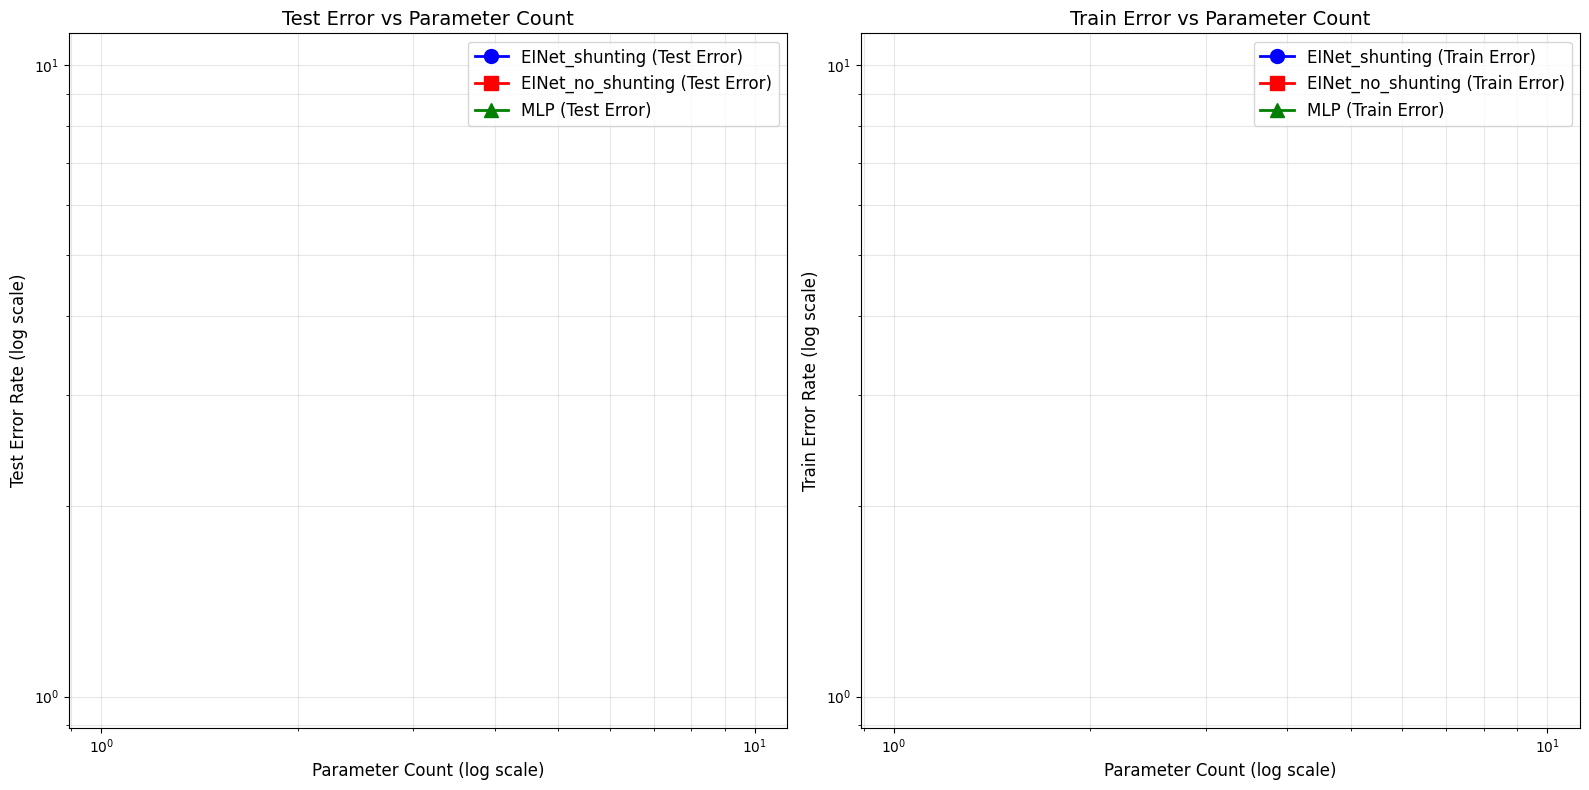

In [7]:
# Cell 7: Main Execution (Completely Replaced)
def run_scaling_notebook(
    config_path='../.vscode/config_exp.yaml', 
    output_dir='results/scaling_experiment', 
    epochs=5
):
    # Experiment configurations
    experiment_configs = {
        "EINet_shunting": {
            "net_type": "EINet",
            "einet_use_shunting": True,
            "einet_reactivation_type": "param_tanh"
        },
        "EINet_no_shunting": {
            "net_type": "EINet", 
            "einet_use_shunting": False,
            "einet_reactivation_type": "param_tanh"
        },
        "MLP": {
            "net_type": "MLP"
        }
    }
    
    # Dimension list for sweeping
    DIM_LIST = [2, 4, 8, 16, 32]
    
    # Run scaling experiment
    results = run_scaling_experiment(
        base_config_path=config_path, 
        dim_list=DIM_LIST, 
        experiment_configs=experiment_configs,
        output_base_dir=output_dir,
        epochs=epochs
    )
    
    # Plot results
    plot_fig = plot_scaling_laws(results)
    plt.show()
    
    return results, plot_fig

# Run the experiment
results, plot_fig = run_scaling_notebook()